<h1 style="text-align: center"> Automobile Fuel Efficiency Prediction & Interpretation </h1>
<h3 style="text-align: center; font-style: italic"> Garudapaksi Yusuf </h3>

---

The **Auto MPG Dataset** from **UCI Machine Learning Repository** provides an excellent foundation for analyzing the key technical factors that influence vehicle fuel efficiency. As fuel economy remains a critical consideration for manufacturers, regulators, and consumers alike, understanding which design attributes most strongly impact miles per gallon (MPG) is essential. This project combines feature analysis with statistical prediction—using machine learning models to uncover how variables such as engine displacement, horsepower, vehicle weight, and cylinder count contribute to fuel performance outcomes.

By applying regression models and interpretability techniques such as feature importance analysis and coefficient evaluation, the project aims to translate raw vehicle specifications into actionable engineering insights. Instead of treating the model as a black box, we leverage explainable machine learning methods to quantify the relative influence of each feature on MPG. The outcome is a data-driven framework that supports design optimization, highlights efficiency trade-offs, and enables informed decision-making in early-stage vehicle development.

---

## Section 1 | Initial Data Analysis

In [1]:
# import required libraries
from ucimlrepo import fetch_ucirepo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyampute.exploration.mcar_statistical_tests import MCARTest
from feature_engine.imputation import DropMissingData
from feature_engine.preprocessing import MatchCategories

### Data Specification

*The first step in data analysis is to set out a full and detailed [specification](https://en.wikipedia.org/wiki/Data_preparation#Data_specification) of the format of each data field and what the entries mean. This especially take careful account of a full understanding of the information available, and any gaps, in the source data.*

#### Data Context

<div align="center">

| <div style="width:170px"> Category </div> | Description |
| --- | --- |
| Source URL | [University of California, Irvine (UCI) Machine Learning Repository: "Auto MPG"](https://archive-beta.ics.uci.edu/dataset/9/auto+mpg) |
| Original Source URL | [Department of Statistics, Carnegie Mellon University (CMU) StatLib Datasets: "cars"](https://lib.stat.cmu.edu/datasets/) |
| License | [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/legalcode) |
| Creation Date | July 7, 1993 |
| Number of Instances | 398 |
| Number of Features | 7 |
| Data Types | Multivariate |
| Associated Tasks | Regression |
| Feature Types | Continuous, Categorical, Integer |


</div>

This dataset is a slightly modified version of the dataset provided in the StatLib library. In line with the use by Quinlan (1993) in predicting the attribute `mpg`, 8 of the original instances were removed because they had unknown values for the `mpg` attribute.

> The data concern city-cycle fuel consumption in miles per gallon, to be predicted in terms of 3 multi-valued discrete and 5 continuous attributes<sup>1</sup>.

<sup>1</sup> Quinlan, R. (1993). Combining Instance-Based and Model-Based Learning. *In Proceedings on the Tenth International Conference of Machine Learning*, 236-243, University of Massachusetts, Amherst: Morgan Kaufmann.

#### Data ETL

In [2]:
def data_etl(id):
    """Fetches data from the UCI repository and prepares it for analysis.
    
    Args:
        id (int): The identifier for the dataset to be fetched from the UCI repository.
    
    Returns:
        pd.DataFrame: A DataFrame containing the features and target variables of the dataset.
    """
    ucirepo_dotdict = fetch_ucirepo(id=id)

    features = ucirepo_dotdict.data.features
    target = ucirepo_dotdict.data.targets

    dataset = pd.concat([features, target], axis=1)

    return dataset

* *[Extract, transform, load (ETL)](https://en.wikipedia.org/wiki/Extract,_transform,_load) is a three-phase computing process where data is extracted from an input source, transformed (to the appropriate format), and loaded into an output data container—or in this case, a variable instance.*
* *Tabel berikut menampilkan 5 sampel baris data dari dataset sebagai contoh hasil ETL:*

In [3]:
# fetch dataset
id_auto_mpg = 9
data = pd.DataFrame(data_etl(id=id_auto_mpg))

# show dataset samples
n_samples = 5
data.sample(n_samples)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
394,97.0,4,52.0,2130,24.6,82,2,44.0
301,105.0,4,70.0,2200,13.2,79,1,34.2
365,200.0,6,88.0,3060,17.1,81,1,20.2
20,110.0,4,87.0,2672,17.5,70,2,25.0
34,225.0,6,105.0,3439,15.5,71,1,16.0


* Setiap baris dalam dataframe merepresentasikan satu *instance* dari car samples.
* Sedangkan kolom dalam dataframe tersebut adalah *variabel* yang mewakili keragaman dari each samples.
    * Beberapa kolom berperan sebagai *feature*, yakni independent variable yang digunakan sebagai input dari suatu model machine learning, dan
    * Kolom pertama merupakan *target*, which is the variable that corresponds to the input data.
* *Untuk kolom `car_name` tidak ikut disertakan dalam proses fetching yang disediakan oleh UCI ML Repository, tetapi kolom ini dapat diakses dengan mengunduh langsung raw data pada [source url]((https://archive-beta.ics.uci.edu/dataset/9/auto+mpg)) dan membuka file `auto-mpg.data`*.

#### Data Dictionary

<div align="center">

| No. | Variable | Role | Type | Description | Units | Missing Values |
| --- | --- | --- | --- | --- | --- | --- |
| <center> 1 </center> | `mpg` | Target | Continuous | *Miles per gallon* | - | <center> No </center> |
| <center> 2 </center> | `displacement` | Feature | Continuous | *Engine displacement* | *cu. inches* | <center> No </center> |
| <center> 3 </center> | `cylinders` | Feature | Integer | *Number of cylinders* | - | <center> No </center> |
| <center> 4 </center> | `horsepower` | Feature | Continuous | *Horsepower* | *hp* | <center> Yes </center> |
| <center> 5 </center> | `weight` | Feature | Continuous | *Weight* | *lbs.* | <center> No </center> |
| <center> 6 </center> | `acceleration` | Feature | Continuous | *Time to accelerate from 0 to 60 miles per hour* | *sec.* | <center> No </center> |
| <center> 7 </center> | `model_year` | Feature | Integer | *Model year* | *modulo 100* | <center> No </center> |
| <center> 8 </center> | `origin` | Feature | Integer | *Origin of car (1: American, 2: European, 3: Japanese)* | - | <center> No </center> |
| <center> 9 </center> | `car_name` | ID | Categorical | *Car manufacturer & type (unique for each instance)* | - | <center> No </center> |

</div>

### Data Inspection

In [4]:
# perform initial inspection on dataset
pd.DataFrame({
    "dtype": data.dtypes,
    "sample": [data[column].unique() for column in data.columns],
    "min": [data[column].min() for column in data.columns],
    "max": [data[column].max() for column in data.columns],
    "duplicated": data.duplicated().sum(),
    "missing": data.isna().sum()
})

,dtype,sample,min,max,duplicated,missing
displacement,float64,"[307.0, 350.0, 318.0, 304.0, 302.0, 429.0, 454...",68.0,455.0,0,0
cylinders,int64,"[8, 4, 6, 3, 5]",3.0,8.0,0,0
horsepower,float64,"[130.0, 165.0, 150.0, 140.0, 198.0, 220.0, 215...",46.0,230.0,0,6
weight,int64,"[3504, 3693, 3436, 3433, 3449, 4341, 4354, 431...",1613.0,5140.0,0,0
acceleration,float64,"[12.0, 11.5, 11.0, 10.5, 10.0, 9.0, 8.5, 8.0, ...",8.0,24.8,0,0
model_year,int64,"[70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 8...",70.0,82.0,0,0
origin,int64,"[1, 3, 2]",1.0,3.0,0,0
mpg,float64,"[18.0, 15.0, 16.0, 17.0, 14.0, 24.0, 22.0, 21....",9.0,46.6,0,0


* Kolom `dtype` menunjukkan jenis tipe data yang ada dalam `data_train`, yang seluruhnya memiliki tipe `float` dan `int`:
    * Tipe data tersebut merepresentasikan random `sample` yang ditunjukkan pada tiap variabel. Semisal `mpg` yang berisikan bilangan desimal `17.5`.
    * `float` mengindikasikan variabel dengan tipe data numerical continuous, sedangkan `int` untuk tipe data numerical discrete.
        * The true nature of `weight` variable is conceptually *continuous*—even if recorded as whole numbers—since they varies smoothly in reality and the measurement resolution in this case is arbitrarily decided.
        * Perlu diperhatikan juga tipe data dari target `mpg` is at the *ratio* level; true zero exists for this variable, which represents the absence of any fuel efficiency.
        * Dan domain knowledge mengindikasikan untuk variabel `origin` memiliki **invalid data type** dan seharusnya bertipe [nominal](https://en.wikipedia.org/wiki/Level_of_measurement#Nominal_level).
* Tidak ada invalid data issue yang terdeteksi:
    * Rentang nilai yang ditunjukkan dari kolom `min` dan `max` secara domain knowledge menunjukkan nilai yang valid, wajar, dan sebenarnya dari car samples.
    * Ambil contoh pada kolom `displacement`, a car's engine displacement bisa berada pada rentang nilai `70.0` hingga `455.0` cubic inches.
* Proses data inspection juga meliputi deteksi terhadap `duplicated` & `missing` data:
    * Tidak ada duplicated data yang terdeteksi, sebagaimana ditunjukkan pada nilai kolom `duplicated` untuk seluruh variabel bernilai `0`, tetapi
    * Terdeteksi adanya **missing data** pada variabel `horsepower`:
        * Sebagaimana ditunjukkan pada nilai kolom `missing` untuk variabel `horsepower` bernilai `6`.
        * Missing data [reduces the representativeness of the sample](https://en.wikipedia.org/wiki/Missing_data#Techniques_of_dealing_with_missing_data) and can therefore distort inferences about the population.

#### Missing Data

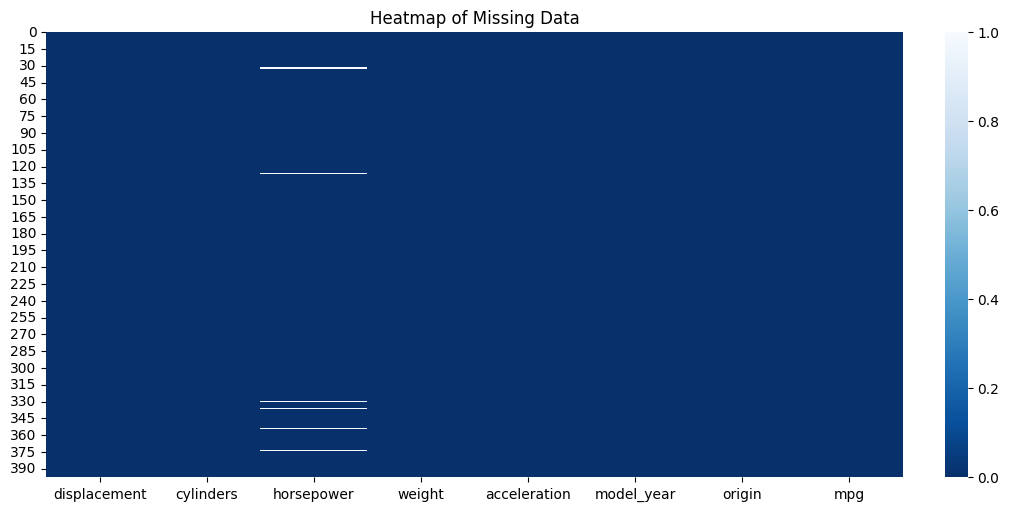

In [5]:
# visualize missing data pattern
width, height = 10, 5
plt.figure(figsize=(width, height), layout="constrained")

sns.heatmap(data.isna().sort_index(), cmap="Blues_r")
plt.title("Heatmap of Missing Data")
plt.show()

*Heatmap di atas menunjukkan:*
* *Garis berwarna putih pada kolom `horsepower` yang merepresentasikan missing data pada kolom tersebut, dan*
* *Sumbu `y` menunjukkan lokasi (indeks) missing data tersebut dalam data.*

Dari visualisasi ini, dapat diinterpretasikan bahwa:
* Missing data terletak pada lokasi yang acak pada `horsepower`; dan
* Missing data terpisah satu sama lain, tidak berdekatan, berhimpitan maupun membentuk pola tertentu.

In [6]:
# slice missing data in dataset
data[data["horsepower"].isnull()]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
32,98.0,4,NaN,2046,19.0,71,1,25.0
126,200.0,6,NaN,2875,17.0,74,1,21.0
330,85.0,4,NaN,1835,17.3,80,2,40.9
336,140.0,4,NaN,2905,14.3,80,1,23.6
354,100.0,4,NaN,2320,15.8,81,2,34.5
374,151.0,4,NaN,3035,20.5,82,1,23.0


*DataFrame di atas menunjukkan:*
* *Sampel dengan missing data pada `horsepower`,*
* *Nilai pada variabel lain dalam data dengan missing data tersebut, dan*
* *Indeks dari missing data dalam data.*

A priori, dapat disimpulkan bahwa:
* Tidak ada indikasi bahwa missing data tersebut are dependent on any other variable.
* Ambil contoh dari kolom `displacement`: missing data memiliki nilai `displacement` yang beragam.

In [7]:
# access p-value from Little's MCAR test results
mcar = MCARTest("little")
pvalue = mcar.little_mcar_test(data)

*Little's MCAR Test<sup>2</sup> adalah:*
* *Statistical hypothesis test untuk Missing Completely At Random (MCAR).*
    * *Null hypothesis: data is MCAR*
    * *Alternative hypothesis: data is not MCAR*
* *Metode yang digunakan adalah chi-square test on the entire data; membandingkan kelompok data dengan missing value terhadap kelompok data tanpa missing value to determine if there is a significant relationship between the two groups.*

<sup>2</sup> Little, R. J. A. (1988). A Test of Missing Completely at Random for Multivariate Data with Missing Values. *Journal of the American Statistical Association, 83*(404), 1198–1202. https://doi.org/10.1080/01621459.1988.10478722

In [8]:
# evaluate Little's MCAR test results
significance_level = 0.05
decision = "Reject H0" if pvalue <= significance_level else "Accept H0"

pd.DataFrame({
    "pvalue": [pvalue],
    "decision": [decision]
})

,pvalue,decision
0,0.313475,Accept H0


* Hasil observasi secara visual dan tabular di atas memberikan inferensi bahwa missing data tersebut adalah MCAR.
* When data is MCAR, there is absolutely no relationship between the data missing and any other values, observed or missing, within the data.
    * In other words, those missing data points are a random subset of the data.
    * There is nothing systematic going on that makes some data more likely to be missing than other.
* If values for observations are missing completely at random, then disregarding those cases would not bias the inferences made.

In [9]:
# discard missing data from dataset
dropper = DropMissingData()
data_dropped = pd.DataFrame(dropper.fit_transform(data), columns=dropper.get_feature_names_out())

* *Transformation yang digunakan pada `data_train` [juga diterapkan pada subsequent datasets](https://scikit-learn.org/stable/common_pitfalls.html#inconsistent-preprocessing), whether it's `data_test` or data in a production system.*
* *Discarding the missing data uses `DropMissingData()` transformer, karena transformer ini compatible dengan Scikit-learn pipeline yang akan digunakan pada bagian-bagian berikutnya.*

#### Invalid Data Type

In [10]:
# encode selected variables in dataset to Pandas' "categorical" data type
unmatched_variable = "origin"
matcher = MatchCategories(
    unmatched_variable,
    ignore_format=True # allow transformer on variables with non-string data type (e.g., numeric)
)
data_cleaned = pd.DataFrame(matcher.fit_transform(data_dropped), columns=matcher.get_feature_names_out())

Variabel `origin` dengan tipe data nominal juga merupakan bagian dari tipe data kategorikal, sehingga `MatchCategories()` transformer dapat digunakan untuk mengubah tipe data variabel tersebut.

#### Inspection Summary

In [11]:
# perform final inspection on cleaned dataset
pd.DataFrame({
    "dtype": data_cleaned.dtypes,
    "missing": data_cleaned.isna().sum()
})

,dtype,missing
displacement,float64,0
cylinders,int64,0
horsepower,float64,0
weight,int64,0
acceleration,float64,0
model_year,int64,0
origin,category,0
mpg,float64,0


* Variabel `origin` yang sebelumnya bertipe integer berhasil dikonversi ke tipe data kategorikal yang sesuai, dan
* Missing data succesfully dropped from the `data_train`.

---

## Section 2 | Exploratory Data Analysis

In [12]:
# import required libraries
import numpy as np
from sklearn.model_selection import train_test_split
from statsmodels.api import add_constant

### Train-Test Split

*The train-test split is a technique for evaluating the performance of a machine learning algorithm. The procedure involves taking a dataset and dividing it into two subsets:*
1. *Train dataset berperan untuk melatih parameter dalam pemodelan —dan akan menjadi fokus analisis on this section—, sedangkan*
2. *Test dataset digunakan untuk mengevaluasi performa model tersebut pada unseen data, ensuring it generalizes well to new examples.*

In [13]:
def inspect_dimensionality(dataset, train, test):
    """Performs dimensionality analysis of the dataset and its train-test subsets.

    Args:
        dataset (pd.DataFrame): The original dataset.
        train (pd.DataFrame): The training subset of the dataset.
        test (pd.DataFrame): The testing subset of the dataset.
        
    Returns:
        pd.DataFrame: A DataFrame summarizing the number of rows, row ratio, 
        and number of columns for the dataset and its subsets.
    """
    dimensionality_summary = pd.DataFrame({
        "row_n": [dataset.shape[0], train.shape[0], test.shape[0]],
        "row_ratio": [dataset.shape[0] / dataset.shape[0], train.shape[0] / dataset.shape[0], test.shape[0] / dataset.shape[0]],
        "column": [dataset.shape[1], train.shape[1], test.shape[1]]
    }, index=["dataset", "train", "test"])
    
    return dimensionality_summary

In [14]:
# set random number generator instance
seed = 42
rng = np.random.RandomState(seed)

*Some scikit-learn `sklearn` objects are [inherently random](https://scikit-learn.org/stable/common_pitfalls.html#controlling-randomness). The randomness of these objects is controlled via their `random_state` parameter.*
* *In order to obtain reproducible (i.e. constant) results across multiple executions of this project, the recommended way is to declare an `rng` variable at the top of the project, and pass it down to any object that accepts a `random_state` parameter.*
* *Random seed yang digunakan secara arbitrary dalam project ini adalah [42](https://en.wikipedia.org/wiki/42_(number)).*

In [15]:
# split dataset to random train and test subsets
train, test = train_test_split(data_cleaned, random_state=rng)
data_train, data_test = pd.DataFrame(train), pd.DataFrame(test)

# perform dimensionality analysis on dataset and its subsets
inspect_dimensionality(data_cleaned, data_train, data_test)

,row_n,row_ratio,column
dataset,392,1.00,8
train,294,0.75,8
test,98,0.25,8


Tabel di atas mendeskripsikan dimensionality dari Auto MPG dataset setelah splitting dilakukan menjadi train dan test subsets:
* Keseluruhan dataset terdiri dari `392` baris dan `8` kolom.
* `train_test_split` membagi `data` tersebut menjadi sepasang `data_train` dan `data_test`.
    * Jumlah baris dalam dataset dibagi menjadi `~0.75/75%` untuk data train dan `~0.25/25%` untuk data test, sesuai default parameter.
    * Splitting ini hanya membagi tiap baris/observasi, sehingga jumlah kolom/variabel tidak berubah.

### Univariate EDA

*Univariate analysis is the simplest form of data analysis, focusing on describing and summarizing a single variable at a time. It analyzes the distribution, central tendency (mean, median, mode), and dispersion (range, variance) to identify patterns, outliers, and data characteristics, rather than examining relationships between variables.*

#### Descriptive Statistics

In [16]:
# subset numerical variables from train set
numerical_train = data_train.select_dtypes("number")

# generate simple descriptive statistics for numerical variables
percentiles = [0.5]
decimals = 2
numerical_train.describe(percentiles).round(decimals)

,displacement,cylinders,horsepower,weight,acceleration,model_year,mpg
count,294.00,294.00,294.00,294.00,294.00,294.00,294.00
mean,195.48,5.47,104.47,2971.83,15.51,76.14,23.69
std,104.66,1.71,38.60,841.77,2.86,3.65,8.01
min,70.00,3.00,46.00,1613.00,8.00,70.00,9.00
50%,151.00,4.00,92.50,2781.50,15.40,76.00,23.00
max,455.00,8.00,230.00,5140.00,24.80,82.00,46.60


*The exact numerical statistics for `numerical_variables` are provided above in tabular format.*
* *`count` refers to the number of non-null values for each columns (similar with `Row/Instance` values in [Section 1: Data Inspection](#data-inspection)),*
* *`mean` measures the [average](https://en.wikipedia.org/wiki/Arithmetic_mean) of the values over each columns,*
* *`std` represents the [standard deviation](https://en.wikipedia.org/wiki/Standard_deviation) for each variables,*
* *`min` and `max` are the minimum and maximum of the values in each columns, respectively, and*
* *`50%` is the corresponding [percentile](https://en.wikipedia.org/wiki/Percentile)—also known as the [median](https://en.wikipedia.org/wiki/Median).*

Terdeteksi adanya perbedaan rentang nilai atau [**order of magnitude**](https://en.wikipedia.org/wiki/Order_of_magnitude) antar variabel numerikal:
* Mulai dari rentang satuan `8.00` pada variabel `acceleration` hingga ribuan `5140.00` pada variabel `weight`.
* Keragaman nilai ini may pose several problems in machine learning:
    * In Linear Regression models, the scale of variables used to estimate the output matters. Linear models are of the type $y = wx + b$, where the regression coefficient $w$ represents the expected change in $y$ for a one unit change in $x$ (the predictor).
    * Thus, the magnitude of $w$ is partly determined by the magnitude of the units being used for $x$. If $x$ is a mass variable, just changing the scale from pounds to grams will cause a change in the magnitude of the coefficient.
* In addition, nilai numerik dari Auto MPG train set berada pada rentang nilai positif (> 0).

#### Visual Analysis

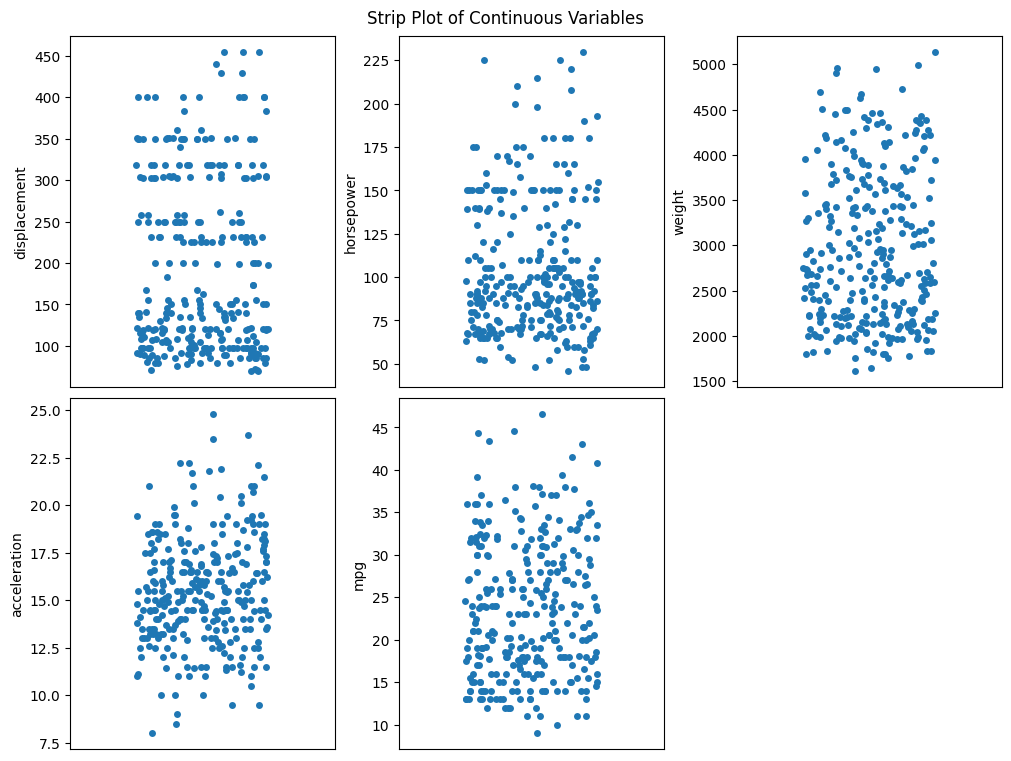

In [17]:
# setup plot figure for continuous variables visualization
width, height = 10, 7.5
plt.figure(figsize=(width, height), layout="constrained")
plt.suptitle("Strip Plot of Continuous Variables")

# subset variables with continuous data type from numerical variables
discrete_columns = ["cylinders", "model_year"]
continuous_train = numerical_train.drop(columns=discrete_columns)

# plot visualization for continuous variables
nrows, ncols = 2, 3
jitter = 0.25
for count, column in enumerate(continuous_train):
    plt.subplot(nrows, ncols, count + 1)
    sns.stripplot(continuous_train, y=column, jitter=jitter)
    plt.xticks(list())

*[Strip plot](https://seaborn.pydata.org/tutorial/categorical.html#categorical-tutorial) digunakan untuk menunjukkan data points berdasarkan continuous numerical variables dalam Auto MPG dataset.*
* *Each dot represent the observation of car samples in Auto MPG dataset.*
* *Karena jumlah observasi dalam dataset dalam rentang ratusan dan relatif banyak, maka `jitter` with a certain value diterapkan untuk memvisualkan data points tersebut secara non-overlapping semaksimal mungkin.*

Beberapa insight dapat ditarik dari visualisasi sederhana ini seperti persebaran data, skewness, hingga distribution gaps. Namun fokus analisa kali ini untuk mendeteksi keberadaan [outlier](https://en.wikipedia.org/wiki/Outlier) pada tiap variabel:
* Dapat dilihat keberadaan clouds of data points seperti pada variabel `displacement & horsepower` yang menandakan adanya [modality](https://en.wikipedia.org/wiki/Mode_(statistics)) of continuous values pada rentang nilai di $y$-axis yang membentuk clouds tersebut.
* Ambil contoh variabel `horsepower`, tampak adanya data point on the upper extremity of the plot, yang merepresentasikan nilai `max (230)` dari variabel tersebut sebagaimana yang telah ditemukan pada bagian sebelumnya dan nilainya berada cukup jauh dari mode of the variable.
* Perlu diperhatikan bahwa extreme value ini tidak jauh berbeda dengan data points di sekitarnya, dan bukanlah sebuah error sebagaimana yang disampaikan pada [Initial Data Inspection](#initial-data-inspection), sehingga ia dapat didefinisikan sebagai *non-outlier*.

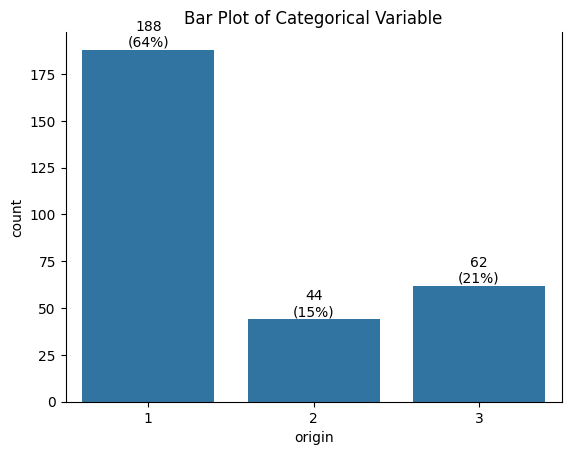

In [18]:
# plot visualization for categorical variables
data_barplot = pd.concat([
    data_train["origin"].value_counts().sort_index(),
    data_train["origin"].value_counts(normalize=True).mul(100)
], axis=1)
axes = sns.barplot(data_barplot, x=data_barplot.index, y="count")

labels = [
    f"{round(value.get_height())}\n({round(data_barplot.iloc[index, 1])}%)"
    for index, value in enumerate(axes.containers[0])
]
axes.bar_label(axes.containers[0], labels=labels)
axes.spines.top.set_visible(False)

plt.title("Bar Plot of Categorical Variable")
plt.show()

*[Bar chart](https://en.wikipedia.org/wiki/Bar_chart) is a chart that presents categorical data with rectangular bars with heights or lengths proportional to the values that they represent.*
* *One axis of the chart shows the specific categories being compared, and the other axis represents a measured value.*
* *Categorical variables are those which values are selected from a group of categories—also called labels.*
* *Tiap grafik dalam plot di atas merepresentasikan labels yang berada dalam variabel tertentu dan occurences (count) dari label tersebut.*
* *Ambil contoh pada variabel `origin`, labels dengan occurences tertinggi adalah `1` sejumlah `183` observations atau `62%` dari keseluruhan data.*

Berdasarkan visualisasi ini, *tidak terdeteksi any particular issue* with the only categorical feature in Auto MPG dataset
* The variable `origin` contains only 3 labels; a definite small number of cardinality
* Meskipun label `1` dari variabel ini mendominasi dengan `64%` frekuensi, tetapi label `2` dan `3` lainnya cukup sering ditemukan dengan masing-masing mencakup `15%` dan `21%` dari keseluruhan data.

### Multivariate EDA

*[Multivariate analysis](https://en.wikipedia.org/wiki/Multivariate_statistics) encompasses the simultaneous observation and analysis of more than one variables, in order to understand the relationships between them and their relevance to the problem being studied. It may also determine to what extent it becomes easier to know and predict a value for one variable (possibly a dependent variable) if the value of the other variable (possibly the independent variable) is known.*

#### Discrete-Dependent Relationship

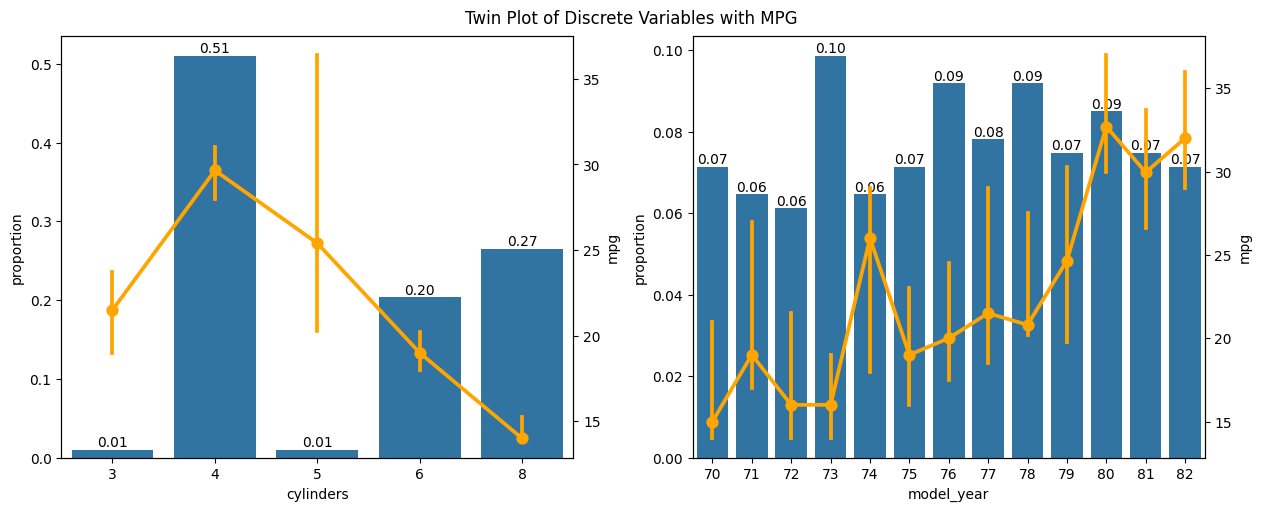

In [19]:
# setup plot figure for discrete variables visualization
width, height = 12.5, 5
plt.figure(figsize=(width, height), layout="constrained")
plt.suptitle("Twin Plot of Discrete Variables with MPG")

# subset variables with discrete data type from numerical variables
continuous_columns = pd.DataFrame(continuous_train).drop(columns="mpg")
discrete_train = numerical_train.drop(columns=continuous_columns)

# plot visualization for discrete variables
nrows, ncols = 1, 2
for count, column in enumerate(discrete_train):
    if column != "mpg":
        plt.subplot(nrows, ncols, count + 1)
        kwargs = dict(data=discrete_train, x=column)

        axes = sns.countplot(**kwargs, stat="proportion")
        axes.bar_label(axes.containers[0], fmt='%.2f')

        axes_twinx = axes.twinx()
        sns.pointplot(
            **kwargs,
            y="mpg",
            estimator="median",
            errorbar="ci",
            seed=rng,
            color="orange",
            ax=axes_twinx,
        )

Visualisasi di atas terdiri dari 2 komponen:
1. [Count plot](https://seaborn.pydata.org/generated/seaborn.countplot.html) shows counts of observations in each discrete values using bars.
    * Instead of counts, `proportion` digunakan to show percentages of labels in `cylinders` and `model_year`.
    * Proportion of labels in `model_year` are comparable —ranging from `0.06` or 6% up to 10%.
    * The same cannot be said for `cylinders`: city-cycle with `4` cylinders represents 51% of the whole Auto MPG dataset, while `3 & 5` **rarely observed** with only 1% for each of them.
2. [Point plot](https://seaborn.pydata.org/generated/seaborn.pointplot.html) represents an estimate of central tendency for the discrete numerical variables by the position of the dot and provides some indication of the uncertainty around that estimate using [error bars](https://seaborn.pydata.org/tutorial/error_bars.html).
    * *The central tendencies for both variables are also defined according to insights found on [Section 2: Statistical Analysis](#statistical-analysis).*
    * *Confidence interval `ci` implemented to exhibit the range of likely values for the true population parameter (`median`) over random samples in Auto MPG.*
    * Median MPG shows an overall upward trend in `model_year`, although not perfectly linear. Analisis berikutnya akan melihat apakah pola serupa terjadi pada variabel lainnya.
    * On the contrary, the median generally decreases as cylinder count increases from `4-8`. With the exception for `3 & 5` cylinders: these cars have tiny sample size, resulting in the unstable estimates (wider `mpg` interval).

For values that are over-represented in the dataset, they tend to dominate the outcome. More specifically:
* A number of infrequent values adds noise with little information, therefore causing over-fitting.
    * Replacing of those labels by either the most frequent value or merging rare values together may be done. But ideally, evaluating the distribution of values within the rares and frequent value should be performed beforehand.
    * Meskipun proporsi `3 & 5` values are similar, perbedaan yang cukup signifikan dapat dilihat dari rentang interval `mpg` dari kedua nilai tersebut, apalagi jika dibandingkan dengan the frequent value of `4` cylinders.
* Rare values may be present in training set, but not in test set, which also causes overfitting to the train set.
    * Conversely, rare values may only appear in test set. thus, the machine learning model will not know how to evaluate it.

#### Linear Regression Fit

In [20]:
def viz_regplot(data_regplot, x_estimator=None, order=1):
    """Visualizes a regression plot using seaborn's regplot function.
    
    This function creates a regression plot for the 'mpg' variable against a specified 
    x variable, allowing for customization of the regression estimator and polynomial order.
    
    Args:
        x_estimator (callable, optional): A function to estimate the x values. 
            If None, the default behavior is used.
        order (int, optional): The order of the polynomial to fit. Default is 1 (linear fit).
    
    Returns:
        None: This function does not return a value but displays the regression plot.
    
    Raises:
        ValueError: If the input data is not valid for regression plotting.
    """
    kwargs = dict(data=data_regplot, x=column, y="mpg", x_estimator=x_estimator, order=order)
    
    sns.regplot(
        **kwargs,
        line_kws={
            "color": "black",
            "linestyle": "dashed",
            "linewidth": 1
        }
    )

    order = 2 # polynomial fit
    sns.regplot(**{**kwargs, "order": order}, scatter=False)

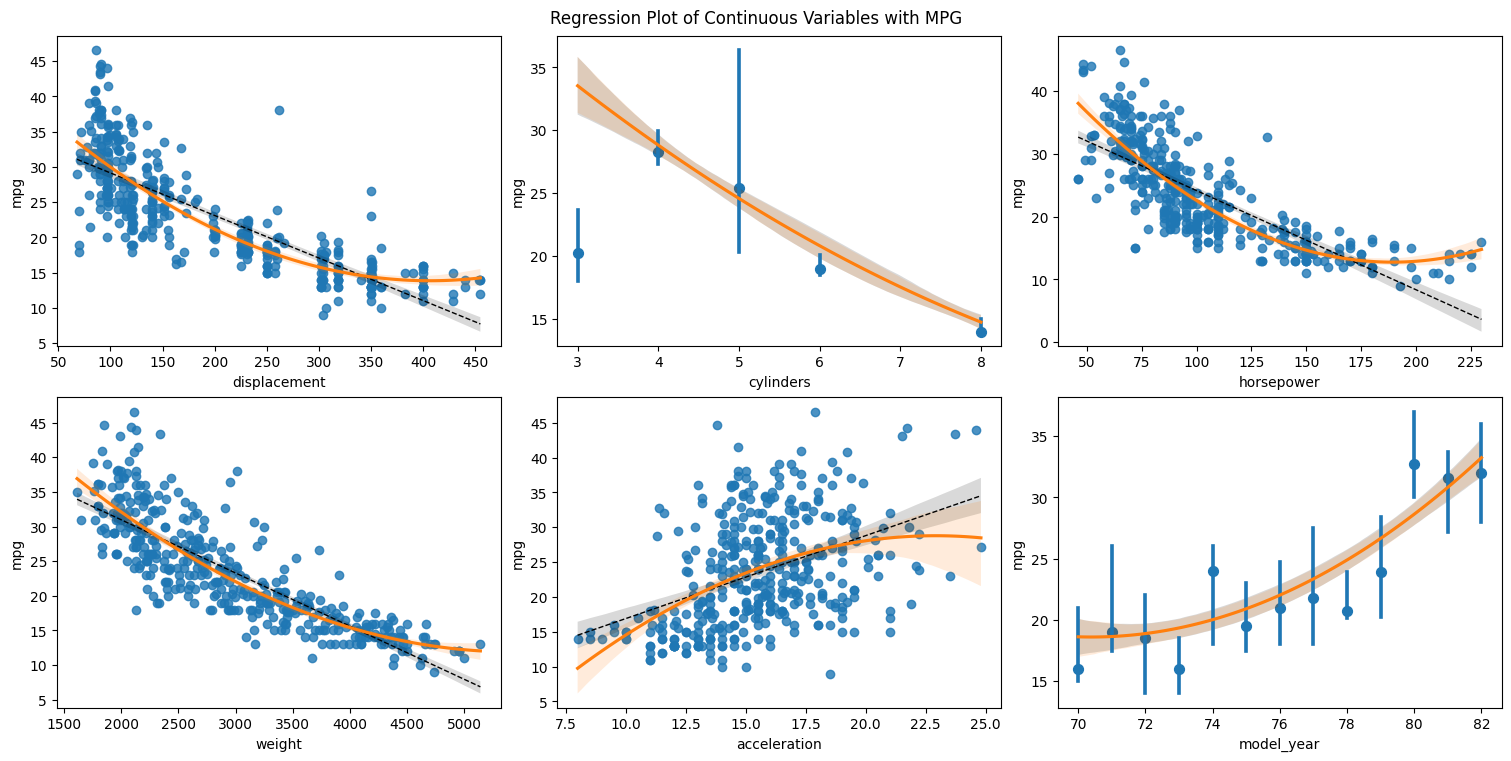

In [21]:
# setup plot figure for linearity visualization
width, height = 15, 7.5
plt.figure(figsize=(width, height), layout="constrained")
plt.suptitle("Regression Plot of Continuous Variables with MPG")

# plot visualization for continuous variables against target variable
nrows, ncols = 2, 3
for count, column in enumerate(numerical_train):
    if column != "mpg":
        plt.subplot(nrows, ncols, count + 1)     
        if column not in discrete_columns:
            viz_regplot(data)
        else:
            viz_regplot(data, np.median, 2)

[Regression plot](https://seaborn.pydata.org/tutorial/regression.html#regression-tutorial) as shown above has two main functions:
1. Depicts the joint distribution of two variables using a scattered cloud of points, where each point represents an observation in the dataset.
    * There is an identifiable negative, **non-linear relationship** between `displacement, horsepower, & weight` against `mpg`.
    * Seiring bertambahnya those variables, fuel efficiency decreases. Pengurangan ini is not strictly linear: sharper at lower and gradual at higher values.
    * And the opposite happens with `model_year` —in positive sign while still displaying non-linearity.
    * Hal ini mengindikasikan bahwa simple linear models may not capture the true relationship between these independent variables against the target.
2. Fit the regression model with $y$ as a function of $x$, and plot the resulting regression line with 95% confidence interval for that regression.
    * Untuk ketiga pasangan variabel yang sama, linear fit deviates at the extremes and misses the pattern, while
    * The polynomial fit is appropriate, since curvature and convex shape is visible from the scatter plot
* *Plot untuk `cylinders` dapat diabaikan karena labels `3 & 5` on the variable are deemed inadequate for the prediction purpose.*
* *Hubungan yang berlawanan didapatkan pada pasangan variabel `acceleration - mpg`: very scattered data points and no clear pattern from the distribution.*

### Analysis Summary

| Anomaly | Description |
| --- | --- |
| Variable Magnitude | Terdeteksi adanya perbedaan magnitude antar numerical variables |
| Rare Values | Teridentifikasi nilai `3 & 5` memiliki proporsi yang jauh lebih rendah dibandingkan nilai lainnya pada variabel `cylinders` |
| Linearity | Tampak adanya non-linear relationship antara several independent variables dengan target variable `mpg` |

---

## Section 3 | Predictive Modeling

In [22]:
# import required libraries
from sklearn.preprocessing import PolynomialFeatures, PowerTransformer, OneHotEncoder
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, make_column_selector, TransformedTargetRegressor
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.metrics import make_scorer, mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold, GridSearchCV

### Feature Engineering

*Feature engineering is a preprocessing step in supervised machine learning and statistical modeling which transforms raw data into a more effective set of inputs.*
* *Each input comprises several attributes, known as features.*
* *By providing models with relevant information, feature engineering significantly enhances their predictive accuracy and decision-making capability.*

#### Rare Values Treatment

In [23]:
class DropValues(BaseEstimator, TransformerMixin):
    """DropValues class for removing specified values from a given column in a DataFrame.
    
    This transformer is designed to be used with scikit-learn's pipeline 
    and allows for the removal of rows in a DataFrame where the specified column contains certain values.
    
    Attributes:
        column (str): The name of the column from which to drop values.
        values (list): A list of values to be removed from the specified column.
    
    Methods:
        fit(X, y=None):
            Fits the transformer to the data. This method is a no-op for this transformer.
    
        transform(X):
            Removes rows from the DataFrame where the specified column contains any of the values to be dropped.
    
    Args:
        column (str): The name of the column to process.
        values (str or list): The value(s) to drop from the specified column. Can be a single value or a list of values.
    """
    def __init__(self, column, values):
        self.column = column
        self.values = values if isinstance(values, list) else [values]

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        mask = ~X[self.column].isin(self.values)
        return X.loc[mask]

* Untuk mengatasi permasalahan noisy rare values of `3 & 5` in `cylinders` variable, custom `DropValues` transformer class digunakan dan rare values tersebut tidak disertakan dalam bagian pemodelan berikutnya.
* Fungsi modeling etl...

In [24]:
# discard rare values from "cylinders" variable in dataset
rare_variable, rare_values = "cylinders", [3, 5]
dropper = DropValues(rare_variable, rare_values)
data_cleaned = pd.DataFrame(dropper.fit_transform(data_cleaned))

cylinders_counts = data_cleaned[rare_variable].value_counts()
pd.DataFrame(cylinders_counts)

,count
cylinders,
4,199
8,103
6,83


* Tabel di atas menampilkan unique labels serta jumlah pada `cylinders` setelah removing rare values from the variable.
* Kemudian another train-test split dilakukan untuk mempersiapkan dataset menuju feature engineering.

In [25]:
# repeat split after discarding rare values
train, test = train_test_split(data_cleaned, random_state=rng)

#### Power Transformer

*Feature scaling through [standardization](https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling)—also called Z-score normalization—is an important preprocessing step for many machine learning algorithms.*
* *Standardization of datasets is a [common requirement](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html#sphx-glr-auto-examples-preprocessing-plot-scaling-importance-py) for many machine learning estimators implemented in Scikit-learn.*
* *They might behave badly if the individual features do not more or less look like standard normally distributed data: Gaussian with zero mean and unit variance, sebagaimana ditunjukkan berikut ini.*
* *Dan considering temuan pada [Section 2: Exploratory Data Analysis](#exploratory-data-analysis) yang menyatakan bahwa variabel numerik dalam Auto MPG dataset berdistribusi non-normal, maka transformasi data menuju Gaussian menggunakan [PowerTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html) diperlukan untuk mempersiapkan data sebelum tahap pemodelan.*

In [26]:
# transform numerical features in train set
transformer = PowerTransformer("box-cox")
numerical_train = pd.DataFrame(data_train).select_dtypes("number")
holdout_transformed = pd.DataFrame(transformer.fit_transform(numerical_train), columns=numerical_train.columns)

# generate descriptive statistics for transformed numerical features
holdout_transformed.describe(percentiles).transpose()

,count,mean,std,min,50%,max
displacement,294.0,2.090542e-15,1.001705,-1.795838,-0.155410,1.715911
cylinders,294.0,1.238616e-15,1.001705,-2.404920,-0.883981,1.328424
horsepower,294.0,-7.504201e-15,1.001705,-2.563668,-0.102099,2.156493
weight,294.0,-6.764053e-15,1.001705,-2.178085,-0.059984,1.987085
acceleration,294.0,-2.477232e-16,1.001705,-3.019346,0.009343,2.913671
model_year,294.0,-1.996891e-15,1.001705,-1.659898,-0.050737,1.631048
mpg,294.0,-5.196146e-16,1.001705,-2.414624,0.044648,2.273473


* *Metode Box-Cox digunakan sesuai temuan pada [Section 2: Visual Analysis](#visual-analysis); karena data [bernilai positif](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html), dan [performs better](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_map_data_to_normal.html#sphx-glr-auto-examples-preprocessing-plot-map-data-to-normal-py) than Yeo-Johnson*.
* Setelah melalui standarisasi, tiap variabel numerik dalam data memiliki `mean` yang mendekati nol. Serta `std` dalam satuan unit yang sama.
* Proses ini juga meratakan order of the magnitude, sehingga nilai tiap variabel are within about a factor of 10 from each other.

#### Polynomial Features

*Sebagaimana yang telah didemonstrasikan pada [Section 2: Linear Regression](#linear-regression), it is useful to add complexity to the model by considering nonlinear features of the data.*
* *A simple and common method to use is [PolynomialFeatures](https://scikit-learn.org/stable/modules/preprocessing.html#generating-polynomial-features), which can get features' high-order terms.*
* *This technique enables linear models to map complex patterns—such as curves—and improve model accuracy when data shows a non-linear relationship.*

In [27]:
class PolynomialWithoutInteractions(BaseEstimator, TransformerMixin):
    """PolynomialWithoutInteractions is a transformer that generates polynomial features without interaction terms.
    
    This class extends `BaseEstimator` and `TransformerMixin` from scikit-learn, allowing it to be used in a pipeline.
    It creates polynomial features of a specified degree and can optionally include a bias term.
    
    Attributes:
        degree (int): The degree of the polynomial features to be generated.
        include_bias (bool): Whether to include a bias (intercept) term in the output.
        generator_ (PolynomialFeatures): An instance of PolynomialFeatures used to generate polynomial features.
        single_feature_term_mask_ (ndarray): A mask indicating which features correspond to single feature terms.
        feature_names_in_ (ndarray or None): The input feature names, if available.
    
    Methods:
        fit(X, y=None):
            Fits the transformer to the input data X and initializes the polynomial feature generator.
    
        transform(X):
            Transforms the input data X into polynomial features, excluding interaction terms.
    
        get_feature_names_out(input_features=None):
            Returns the output feature names for the transformed data, excluding interaction terms.
    """

    def __init__(self, degree, include_bias):
        self.degree = degree
        self.include_bias = include_bias

    def fit(self, X, y=None):
        self.generator_ = PolynomialFeatures(
            degree=self.degree,
            include_bias=self.include_bias,
        )
        self.generator_.fit(X)
        self.single_feature_term_mask_ = (self.generator_.powers_ > 0).sum(axis=1) <= 1
        self.feature_names_in_ = getattr(self.generator_, "feature_names_in_", None)
        return self

    def transform(self, X):
        polynomial_features = self.generator_.transform(X)
        return polynomial_features[:, self.single_feature_term_mask_]

    def get_feature_names_out(self, input_features=None):
        feature_names = self.generator_.get_feature_names_out(input_features)
        return feature_names[self.single_feature_term_mask_]

In [28]:
# generate polynomial features without interaction terms
degree = 2
numerical_features = holdout_transformed.drop(columns="mpg", errors="ignore")
polynomial = PolynomialWithoutInteractions(
    degree=degree,
    include_bias=False,
)
holdout_numerical = pd.DataFrame(
    polynomial.fit_transform(numerical_features),
    columns=polynomial.get_feature_names_out(numerical_features.columns),
)

# generate descriptive statistics for polynomial features
holdout_numerical.sample(n_samples).transpose()

,235,52,63,140,202
displacement,-1.061606,1.456142,-1.545697,-1.061606,-0.579734
cylinders,-0.883981,1.328424,-0.883981,-0.883981,-0.883981
horsepower,-0.118368,1.504833,-2.075115,-0.253798,-0.553263
weight,-0.784204,0.805828,-1.335075,-1.114197,-0.524724
acceleration,0.557222,-2.094907,1.332021,0.388938,0.388938
model_year,-1.131740,-1.659898,0.501912,-1.131740,-0.595320
displacement^2,1.127008,2.120349,2.389179,1.127008,0.336092
cylinders^2,0.781422,1.764710,0.781422,0.781422,0.781422
horsepower^2,0.014011,2.264522,4.306103,0.064413,0.306100
weight^2,0.614976,0.649358,1.782426,1.241435,0.275335


* Polynomial features are generated on numerical features—including the discrete `cylinders & model_year` variables,
    * Karena the values are ordered (ex. year `70 - 82`) and there are meaningful distances between them (e.g. between `3 - 4` in `cylinders` is exactly 1 cylinder).
    * Contrasts with categorical features where squaring them are nonsensical (for example, $2^2$ value in `origin^2` doesn't mean anything).
    * *`include_bias` parameter set to `False` agar tidak terjadi duplikasi bias term (intercept) dengan [chosen downstream model](#modeling-pipeline).*
* `PolynomialFeatures` introduces the problem of **feature expansion**, where the number of features increases dramatically.
    * It is expected for several polynomial—especially for interaction terms such as `displacement cylinders`—to be highly correlated with the original feature.
    * Hence, creating new predictors that may further be deemed redundant than before.
    * Model complexity also increases with the number of independent variables, sehingga model yang appropriate akan implemented to handle these problems.

#### One-Hot Encoding

*Most machine learning models operate on mathematical computations—requiring numbers, not text.*
* *Sehingga encoding diperlukan untuk mengubah data dalam bentuk teks seperti categorical features menjadi numerik.*
* *Teknik encoding yang digunakan kali ini adalah yang paling umum diterapkan, yakni [one-hot encoding](https://scikit-learn.org/stable/modules/preprocessing.html#encoding-categorical-features). One-hot encoding transforms each categorical features with $n$ possible values into $n$ binary features, with one of them 1, and all others 0.*

In [29]:
# encode categorical features in train set
encoder = OneHotEncoder(drop="first", sparse_output=False)
categorical_train = pd.DataFrame(data_train).select_dtypes("category")
holdout_categorical = pd.DataFrame(encoder.fit_transform(categorical_train), columns=encoder.get_feature_names_out())

# inspect categorical features after encoding
pd.DataFrame(holdout_categorical).sample(n_samples)

,origin_2,origin_3
7,0.0,0.0
242,0.0,1.0
258,0.0,0.0
127,1.0,0.0
183,0.0,1.0


DataFrame di atas menampilkan hasil dari encoding pada 5 sample baris dari data train:
* *`drop="first"` dan `sparse_output=False` parameters digunakan untuk menghindari [dummy variable trap](https://en.wikipedia.org/wiki/Dummy_variable_(statistics)) dan sparse matrix (["NaN"](https://pandas.pydata.org/docs/user_guide/sparse.html)) issue —respectively— pada analisis korelasi di bagian berikutnya.*
* Satu categorical variable `origin` yang memiliki 3 label diubah menjadi 2 numerical variable terpisah `origin_2 & origin_3`.
    * Tiap variabel tersebut hanya memiliki 2 kemungkinan nilai di dalamnya yakni `0 & 1`.
    * `0` menandakan suatu observasi bukan bagian dari variabel tersebut dan sebaliknya untuk nilai `1`.

#### Multicollinearity Analysis

*[Multicollinearity](https://en.wikipedia.org/wiki/Multicollinearity) is a situation where the predictors in a model are linearly dependent; when one feature can be written as an exact —or nearly exact, as in the case of imperfect multicollinearity— linear function of the others.*
* *Collinearity may arise from generating polynomial features as implemented previously in [Section 3: Feature Engineering](#polynomial-features), because the columns are deterministic transformations of the same original variables, so they become strongly related with each other.*
* *Similarly, by including one-hot dummy variables for every label in a categorical feature, their sum would equal to 1 for all observations, which is identical to and hence perfectly correlated with the vector-of-ones —a.k.a. constant/intercept term— *if it were also present (will be demonstrated further)*.*
* *To address multicollinearity, [Variance Inflation Factor](https://en.wikipedia.org/wiki/Variance_inflation_factor) (VIF) can be used to identify the collinearity of the predictor variables:*

In [30]:
# add intercept term to preprocessed features for VIF calculation
holdout_features = pd.concat([holdout_numerical, holdout_categorical], axis=1)
exog = add_constant(holdout_features)

# calculate VIF for each variable
df_vif = pd.DataFrame([
    variance_inflation_factor(exog.values, index)
    for index in range(exog.shape[1])
], index=exog.columns, columns=["vif"])
df_vif.sort_values("vif")

,vif
model_year^2,1.151644
model_year,1.445830
acceleration^2,1.878321
origin_2,1.987980
origin_3,2.298384
horsepower^2,2.970084
cylinders^2,3.109928
weight^2,3.367383
acceleration,3.959349
displacement^2,5.523525


* *VIF is numerical ratio of the variance of a parameter estimate (e.g. estimated coefficient of the predictor) when fitting a full model that includes other parameters, to the variance of the parameter estimate if the model is fit with only the parameter of its own.*
    * *Square root of the variance inflation factor indicates how much larger the standard error increases compared to if that variable had zero correlation to other predictor variables in the model.*
    * *[`variance_inflation_factor()`](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html) implementation from Statsmodels library uses ordinary least square as auxiliary regression to calculate the VIF value, sehingga constant term perlu ditambahkan ke transformed data as input to the model via `add_constant()` function.*
* Take the first example of `model_year^2` with `vif` value of `1.612957`, sehingga akar kuadratnya adalah 0.8064785. 
    * This means that the standard error for the coefficient of `model_year` is 0.96 times larger than conditional of zero correlation with other predictors, or in other words, `model_year` has minimal correlation with any predictors in the model.
    * Jika dibandingkan dengan `displacement weight` with `vif` value of `373.293496` —resulting in square root value of 186.646748—, this particularly high value is beyond the common threshold used in determining a high level of **multicollinearity** and would lead to poor estimate of the parameter.
        * The problem with trying to identify how much of the variable matters is that it is confounded with the other; i.e. observations are explained equally well by either `displacement`, `weight`, or even `displacement weight` variable —since the particular polynomial is calculated from the original features. 
        * So it is impossible to know which one of them causes the observed correlations.

#### Preprocessing Summary

| Anomaly | Description |
| --- | --- |
| Rare Values | `DropValues` discard rare labels `3 & 5` from `cylinders` |
| Variable Magnitude | `PowerTransformer` put the independent variables on a comparable scale/order of magnitude |
| Linearity | `PolynomialFeatures` introduce nonlinear relationship against the target variable into model yang akan digunakan |
| Feature Expansion | *To be analyzed further in [Section 3: Modeling Pipeline](#modeling-pipeline)* |
| Encoding | `OneHotEncoder` applied as basic prerequisite for inputting categorical feature to machine learning algorithm |
| Multicollinearity | *To be analyzed further in [Section 3: Modeling Pipeline](#modeling-pipeline)* |

### Modeling ETL

In [31]:
def feature_target_split(dataset, random_state):
    """Splits a dataset into training and testing sets for features and target variable.
    
    Args:
        dataset (pandas.DataFrame): The input dataset containing features and target variable.
        random_state (int): The seed used by the random number generator for reproducibility.
    
    Returns:
        tuple: A tuple containing:
            - X_train (pandas.DataFrame): The training set features.
            - X_test (pandas.DataFrame): The testing set features.
            - y_train (pandas.Series): The training set target variable.
            - y_test (pandas.Series): The testing set target variable.
    """
    X, y = pd.DataFrame(dataset).drop(columns="mpg"), pd.Series(dataset["mpg"])
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=random_state)

    return X_train, X_test, y_train, y_test

*In machine learning:*
* *Features are the input variables (independent variables) used to make predictions, while*
* *The target is the variable to be predicted or understood (dependent variable).*
* *Together, they form the basis for supervised learning, where features map to a target value. Features are selected for relevance, and the target is the goal.*

In [32]:
# split features and target to random train and test subsets
X_train, X_test, y_train, y_test = feature_target_split(data_cleaned, rng)

# perform dimensionality analysis of train-test subsets
inspect_dimensionality(data_cleaned, X_train, X_test)

,row_n,row_ratio,column
dataset,385,1.000000,8
train,288,0.748052,7
test,97,0.251948,7


Proses splitting di atas kurang lebih serupa dengan yang telah dilakukan pada [Section 2: Train-Test Split](#train-test-split), dengan beberapa perbedaan:
* `feature_target_split` membagi `data` menjadi 2 pasang `X_train - X_test` dan `y_train - y_test`.
* Proporsi pembagian dataset ini tetap sama, namun karena target variabel `mpg` turut dipisahkan menjadi `y_train & y_test`, jumlah kolom pada `train & test`—dengan kata lain, `X_train & X_test`—berkurang 1 variabel.

In [33]:
def modeling_etl(id, random_state):
    """Modeling ETL process for data preparation.
    
    This function performs an Extract, Transform, Load (ETL) process on the dataset identified by the given ID.
    It includes steps to drop missing data, match categories, and drop specific values from the dataset.
    The cleaned data is then split into training and testing features and targets.
    
    Args:
        id (int): The identifier for the dataset to be processed.
        random_state (int): The random state for reproducibility of the train-test split.
    
    Returns:
        tuple: A tuple containing:
            - train_features (DataFrame): The features for the training set.
            - test_features (DataFrame): The features for the testing set.
            - train_target (Series): The target variable for the training set.
            - test_target (Series): The target variable for the testing set.
    """
    drop_missing = DropMissingData()
    match = MatchCategories(unmatched_variable, ignore_format=True)
    drop_values = DropValues(rare_variable, rare_values)
    pipeline = make_pipeline(drop_missing, match, drop_values)

    data = data_etl(id)
    data_cleaned = pipeline.fit_transform(data)
    
    train_features, test_features, train_target, test_target = feature_target_split(data_cleaned, random_state)

    return train_features, test_features, train_target, test_target

In [34]:
# extract, transform, and load data for modeling
X_train, X_test, y_train, y_test = modeling_etl(id_auto_mpg, rng)

### Modeling Pipeline

In [35]:
def modeling_pipeline(alpha, l1_ratio, max_iter=10000):
    """Creates a modeling pipeline for regression tasks using ElasticNet with preprocessing steps for numerical and categorical features.
    
    Args:
        alpha (float): The constant that multiplies the L1 term in the ElasticNet penalty.
        l1_ratio (float): The ElasticNet mixing parameter, with 0 <= l1_ratio <= 1. 
                          For l1_ratio = 0 the penalty is an L2 penalty. 
                          For l1_ratio = 1 it is an L1 penalty.
        max_iter (int, optional): The maximum number of iterations for the ElasticNet solver. Defaults to 10000.
    
    Returns:
        Pipeline: A scikit-learn Pipeline object that includes preprocessing for numerical and categorical features,
                  and a transformed target regressor using ElasticNet.
    """
    transformer = PowerTransformer("box-cox")
    polynomial = PolynomialWithoutInteractions(degree=degree, include_bias=False)
    numerical_preprocessor = make_pipeline(transformer, polynomial)

    encoder = OneHotEncoder(drop="first", sparse_output=False)
    categorical_preprocessor = make_pipeline(encoder)
    preprocessor = ColumnTransformer([
        ("NumericalPreprocessor", numerical_preprocessor, make_column_selector(dtype_include="number")),
        ("CategoricalPreprocessor", categorical_preprocessor, make_column_selector(dtype_include="category"))
    ], verbose_feature_names_out=False)

    regressor = ElasticNet(
        alpha,
        l1_ratio=l1_ratio,
        fit_intercept=True,
        max_iter=max_iter,
        random_state=rng
    )
    transformed_target_regressor = TransformedTargetRegressor(regressor=regressor, transformer=transformer)
    
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("transformedtargetregressor", transformed_target_regressor)
    ])

    return pipeline

Langkah-langkah yang diterapkan dalam pembuatan [pipeline](https://scikit-learn.org/stable/modules/compose.html#pipeline) untuk pemodelan adalah sebagai berikut:
1. Dimulai dengan mengintegrasikan feature engineering sesuai tahapan [Section 2: Data Preprocessing](#data-preprocessing) ke dalam satu `preprocessor`, yakni:
    * Menggabungkan `PowerTransformer, PolynomialFeatures, & StandardScaler` beserta parameter yang telah ditetapkan dengan menggunakan [`make_pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html) shorthand dan menerapkannya ke numerical features secara otomatis melalui [`make_column_selector`](https://scikit-learn.org/stable/modules/generated/sklearn.compose.make_column_selector.html), dan
    * Memisahkan `OneHotEncoder` dari pipeline tersebut karena akan diterapkan khusus pada categorical feature `origin`.
2. Memilih [`ElasticNet`](https://scikit-learn.org/stable/modules/linear_model.html#elastic-net) sebagai baseline predictor yang dapat menangani permasalahan:
    1. Multicollinearity: by imposing [$l_2$ regularization](https://scikit-learn.org/stable/auto_examples/linear_model/plot_ridge_coeffs.html) to the loss function (residual sum of squares), this penalty discourages any feature coefficient from taking an excessively large value, and encourages smaller and more evenly distributed coefficients.
    2. Feature expansion: also by imposing [$l_1$ penalization](https://scikit-learn.org/stable/modules/linear_model.html#lasso) to the same loss function, a sparsity constraint is introduced to the feature coefficients, encouraging some of them to be zero—therefore reduced dimensionality and simpler model interpretation.
    * *By default, `ElasticNet` included an [intercept](https://en.wikipedia.org/wiki/Linear_regression#Intercept) constant (with `fit_intercept=True`) as one of the linear regressor to be estimated.*
    * *`ElasticNet` also uses a [coordinate descent](https://scikit-learn.org/stable/auto_examples/linear_model/plot_lasso_lasso_lars_elasticnet_path.html#lasso-lasso-lars-and-elastic-net-paths) method to compute the regularization paths, with iterative optimization to solve the objective function.*
        * *Dengan mempertimbangkan penggunaan polynomial features with both modes of regularizations, maka parameter `max_iter` increased arbitrarily and moderately (from default value of 1000) to stabilize the model training convergence.*
        * *No statistical downside to increasing `max_iter` except slightly longer training time.*

3. Menggunakan `TransformedTargetRegressor` dengan tujuan utama untuk [improve predictions](https://scikit-learn.org/stable/auto_examples/compose/plot_transformed_target.html#sphx-glr-auto-examples-compose-plot-transformed-target-py) terhadap target `mpg`,
    * Yang telah dipisahkan dari dataset menjadi feature variables `X` dan target variable `y`
    * Preprocessing yang dilakukan adalah `PowerTransformer` seperti halnya yang telah dilakukan pada feature variables `X`
4. Menggabungkan keseluruhan elemen tersebut ke dalam satu `pipeline`.
    * ...
    * Setelah menetapkan default [hyper-parameter](https://scikit-learn.org/stable/modules/grid_search.html#tuning-the-hyper-parameters-of-an-estimator) dari `ElasticNet`, berikutnya ditampilkan non-fitted pipeline yang akan digunakan dalam pemodelan.

In [36]:
# set default regularization strength for ElasticNet regression
alpha = 1
l1_ratio = 0.5

# initialize and display modeling pipeline
estimator = modeling_pipeline(alpha, l1_ratio)
estimator

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('transformedtargetregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('NumericalPreprocessor', ...), ('CategoricalPreprocessor', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float

### Hyperparameter Tuning

*[Hyper-parameters](https://scikit-learn.org/stable/modules/grid_search.html#tuning-the-hyper-parameters-of-an-estimator) are parameters that are not directly learnt within estimators. In scikit-learn they are passed as arguments to the constructor of the estimator classes.*

In [37]:
# setup hyperparameter grid space
param_name_alpha = "transformedtargetregressor__regressor__alpha"
start, stop, num = -4, 4, 9
param_range_alpha = np.logspace(start, stop, num)

param_name_l1_ratio = "transformedtargetregressor__regressor__l1_ratio"
start, stop, num = 0.1, 0.9, 9
param_range_l1_ratio = np.linspace(start, stop, num)

param_grid = {
    param_name_alpha: param_range_alpha,
    param_name_l1_ratio: param_range_l1_ratio
}

* `alpha & l1_ratio` parameters dari ElasticNet `regressor` telah diintegrasikan ke dalam `transformedtargetregressor` class, sehingga rangkaian nama parameter ini yang digunakan dalam hyperparameter tuning.
* In the initial search, commonly used logarithmic scale and linear space for possible `alpha & l1_ratio` values, respectively, are chosen.
    * For `alpha` values, the space is centered on the default value of 1 and expand symmetrically.
    * Sementara untuk `l1_ratio`, the space are maintained in range of `0 < l1_ratio < 1` to avoid both pure penalties of 0 ($l_2$) and 1 ($l_1$).
    * Setelah tuning dilakukan dan parameter terbaik didapatkan, narrower/granular search dapat dilakukan untuk meningkatkan performa model.

In [38]:
# generate scorer from defined loss function
scoring = {
    "neg_mse": make_scorer(mean_squared_error, greater_is_better=False),
    "neg_rmse": make_scorer(root_mean_squared_error, greater_is_better=False),
    "neg_mae": make_scorer(mean_absolute_error, greater_is_better=False),
    "r2": make_scorer(r2_score)
}

Four [evaluation metrics](https://scikit-learn.org/stable/glossary.html#term-evaluation-metrics) for regression ditetapkan to give a measure of how well the model performs:
1. [Mean Squared Error](https://scikit-learn.org/stable/modules/model_evaluation.html#mean-squared-error) `mse` ditentukan sebagai loss function which will be optimized in this tuning section. Although not [stricly consistent](https://en.wikipedia.org/wiki/Scoring_rule), but still aligns with the objective function of ElasticNet, namely penalized ($l_2 + l_1$) residual sum of squares.
2. Root Mean Squared Error `rmse` comes from taking the square root of the `mse`, which provides a measure in the same units as the target variable for easier interpretation of aforementioned metric.
3. [Mean Absolute Error](https://en.wikipedia.org/wiki/Mean_absolute_error) corresponds to the expected value of the absolute error loss. This is in contrast to `rmse` which involves squaring the differences, so that a few large differences will increase the `rmse` to a greater degree than the `mae`.
4. [Coefficient of Determination](https://scikit-learn.org/stable/modules/model_evaluation.html#r2-score-the-coefficient-of-determination) `r2` represents the proportion of variance (of the target variable) that has been explained by the independent variables in the model; providing an indication of goodness of fit and therefore a measure of how well unseen samples are likely to be predicted by the model.
* *`greater_is_better` parameters are set to `False` karena metrics such as `mse, rmse, & mae` merupakan [loss function](https://en.wikipedia.org/wiki/Loss_function) in which the model seeks to minimize —meaning lower is better instead.*
    * *In this case, the `scoring` object will sign-flip the outcome of `score_func`, sehingga name value dari object ini pun disesuaikan (e.g. `mse` to `neg_mse`).*
    * *Best possible score for `r2` is 1.0, sehingga the parameter for this metric is left to the default state `greater_is_better=True`.*

In [39]:
# setup cross-validation methods
n_splits_inner, n_splits_outer = 5, 10
kwargs = dict(shuffle=True, random_state=rng)
inner_cv, outer_cv = KFold(n_splits_inner, **kwargs), KFold(n_splits_outer, **kwargs)

*[Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) berkaitan dengan metodologi dalam supervised machine learning to avoid overfitting and data leakage.*
* *Selaras dengan informasi yang didapatkan dari [Section 1: Data Dictionary](#data-dictionary) bahwasanya kolom `car_name` dari Auto MPG dataset berfungsi sebagai unique identifier for each car instance, it may be approximately inferred bahwa sample dalam dataset ini are [independent and identically distributed](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators) (i.i.d.).*
* *Dengan demikian, cross-validators such as K-Fold, Repeated K-Fold, and Shuffle Split dapat digunakan as the specific methods dan hyperparameter tuning procedure over the defined space diterapkan to search for the best cross-validation scores.*

Default choice of `KFold` and its parameters digunakan dalam tahapan-tahapan berikutnya.
* *If desired, Repeated K-Fold dapat memberikan hasil estimasi yang lebih stabil, with higher computation cost or training time.*
* Dengan mengatur `shuffle=True`, akan didapatkan fold yang merepresentasikan mixtures of car observations and improves the reliability for future model evaluation. Selain itu, diasumsikan juga bahwa rows in the dataset are ordered arbitrarily and without any meaning behind the collection.

In [40]:
# perform hyperparameter search over nested cross-validation procedure
n_jobs = -1
search = GridSearchCV(
    estimator,
    param_grid=param_grid,
    scoring=scoring,
    n_jobs=n_jobs,
    refit="neg_mse",
    cv=inner_cv
)

*Dengan mempertimbangkan limited hyperparameter space yang telah ditetapkan sebelumnya, maka [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) dapat digunakan to exhaustively search over the specified parameter values for the estimator.*
* *[`n_jobs`](https://scikit-learn.org/stable/glossary.html#term-n_jobs) set to `-1` to use all processors running concurrently and in parallel —hastening the computation required to search over the parameter space and several data splits from cross-validation.*
* *For multiple metric evaluation yang telah ditetapkan sebelumnya, `refit` parameter needs to be a string denoting the scorer that would be used to find the best parameters for refitting the estimator at the end —in this case, `neg_mse` as stated beforehand.*

[Nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html#nested-versus-non-nested-cross-validation) digunakan to further avoid data leakage dengan memisahkan data folds yang digunakan in the:
* `inner_cv` loop (here executed by `GridSearchCV`), which approximately optimize the score by fitting the model to each training set, and then directly optimized in selecting hyperparameters over the validation set;
* `outer_cv` loop (implemented on `cross_val_score` afterwards) which estimates generalization error by averaging test set scores over another dataset splits.
* Default value of `5` is chosen for the number of splits in `inner_cv`, with double the size in `outer_cv` as an attempt to balance the computational cost and representative performance of the model.

And finally, `search` estimator with the best hyperparameter found from `GridSearchCV` is [fitted](https://scikit-learn.org/stable/glossary.html#term-fit) to the whole train set as implemented below.

In [41]:
# fit model with the best hyperparameters over the train set
search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...'box-cox')))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'transformedtargetregressor__regressor__alpha': array([1.e-04... 1.e+04]), 'transformedtargetregressor__regressor__l1_ratio': array([0.1, 0....7, 0.8, 0.9])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'neg_mae': make_scorer(m...hod='predict'), 'neg_mse': make_scorer(m...hod='predict'), 'neg_rmse': make_scorer(r...hod='predict'), 'r2': make_scorer(r...hod='predict')}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'neg_mse'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versioncha

---

## Section 4 | Model Inspection

In [42]:
# import required libraries
from sklearn.model_selection import cross_validate
from yellowbrick.model_selection import LearningCurve
from yellowbrick.regressor import PredictionError, ResidualsPlot
import shap

### Model Evaluation

*Model evaluation measure how well machine learning models accomplish their intended tasks. Evaluation functions —using different metrics and techniques— quantify performance, reveal weaknesses, and guide improvement.*

#### Evaluation Metrics

In [43]:
# show hyperparameters grid space
df_params = pd.DataFrame({
    "param_range_alpha": [param_range_alpha],
    "param_range_l1_ratio": [param_range_l1_ratio]
}, index=["value"])
display(df_params.transpose().style.set_caption("Defined hyperparameters grid space"))

# show chosen hyperparameters from inner_cv
df_cv_params = pd.DataFrame([search.cv_results_["params"][search.best_index_]], index=["value"])
display(df_cv_params.transpose().style.set_caption(caption="Best hyperparameters from inner_cv"))

,value
param_range_alpha,[1.e-04 1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03 1.e+04]
param_range_l1_ratio,[0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]


,value
transformedtargetregressor__regressor__alpha,0.010000
transformedtargetregressor__regressor__l1_ratio,0.400000


Berikutnya ditampilkan chosen hyperparameters from inner $k$-fold cross-validation loop.
* Untuk nilai `alpha` yang dipilih adalah `0.01`. With this small amount of $l_2$ regularization relative to the possible range of `alpha` as stated in [Section 3: Hyperparameter Tuning](#hyperparameter-tuning), the model [captures](https://scikit-learn.org/stable/auto_examples/linear_model/plot_ridge_coeffs.html#sphx-glr-auto-examples-linear-model-plot-ridge-coeffs-py) enough of the intricate details of the training data —whether those were caused by noise or by actual information— without risking any more of the model performance if the coefficient increases.
* Meanwhile, the best $l_1$ ratio of `0.4` sits quite on the middle of the search grid, balancing the effects between $l_2$ shrinkage and $l_1$ forcing few of the features to zero *(will be shown in further steps of this section)*.

In [44]:
# show cross-validated scores from outer_cv
kwargs = dict(estimator=search.best_estimator_, cv=outer_cv, n_jobs=-1)
cv_scores = cross_validate(**kwargs, X=X_train, y=y_train, scoring=scoring)
df_cv = pd.DataFrame({
    "mse": [abs(np.mean(cv_scores["test_neg_mse"])), np.std(cv_scores["test_neg_mse"])],
    "rmse": [abs(np.mean(cv_scores["test_neg_rmse"])), np.std(cv_scores["test_neg_rmse"])],
    "mae": [abs(np.mean(cv_scores["test_neg_mae"])), np.std(cv_scores["test_neg_mae"])],
    "r2": [np.mean(cv_scores["test_r2"]), np.std(cv_scores["test_r2"])]
}, index=["mean", "std"])
display(df_cv.style.set_caption(caption="Cross-validated scores from outer_cv"))

# show test scores
y_pred = pd.Series(search.best_estimator_.predict(X_test), index=y_test.index, name="mpg_pred")
df_pred = pd.DataFrame({
    "mse": [mean_squared_error(y_test, y_pred)],
    "rmse": [root_mean_squared_error(y_test, y_pred)],
    "mae": [mean_absolute_error(y_test, y_pred)],
    "r2": [r2_score(y_test, y_pred)]
}, index=["value"])
display(df_pred.style.set_caption(caption="Test scores from best estimator fitted on train set"))

,mse,rmse,mae,r2
mean,7.349786,2.686153,1.921935,0.875206
std,1.972158,0.366560,0.247209,0.041391


,mse,rmse,mae,r2
value,7.240818,2.690877,1.883966,0.871606


Setelah itu, ditampilkan average `mean()` and variation `std()` of the scoring values computed in the outer cross-validation procedure.
* *Note that since the scoring is sign-flipped, maka nilai absolute `abs()` digunakan untuk memudahkan interpretasi dari nilai rerata tersebut.*
* `cv_scores` values serve as the **baseline [unbiased estimate](https://en.wikipedia.org/wiki/Bias_of_an_estimator) for the model's performance/generalization**.
* Additionally, `test scores` disertakan untuk melihat konsistensi dari performa model against the true out-of-sample performance. With the scores close to the mean and still within the standard deviation of `cv_scores`, it can be inferred that the model generalizes similarly to cross-validation expectations.

#### Learning Curve

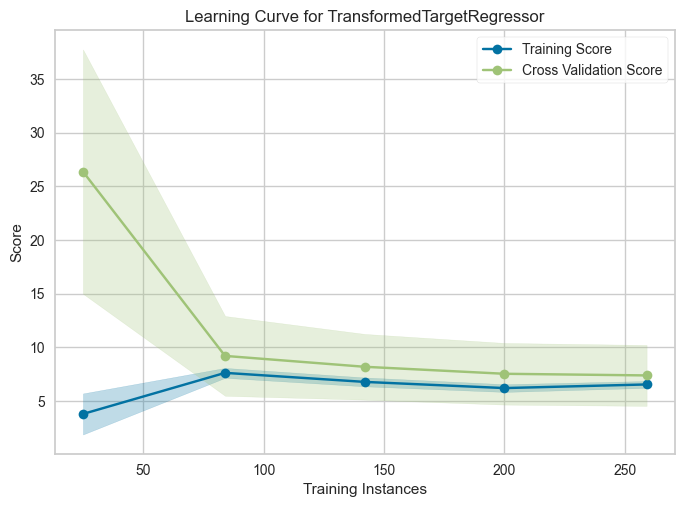

In [45]:
def scoring_mse_negated(estimator, X, y):
    """Calculates the negated mean squared error for a given estimator.
    
    Args:
        estimator: The estimator object implementing the fit and predict methods.
        X: The input data to score, typically a 2D array-like structure.
        y: The true target values corresponding to the input data.
    
    Returns:
        float: The negated mean squared error of the estimator on the provided data.
    """
    return -scoring["neg_mse"](estimator, X, y)

# visualize learning curve of the model
visualizer = LearningCurve(
    **kwargs,
    scoring=scoring_mse_negated,
    force_model=True # prevent estimator type exception in fitting the visualizer
)

visualizer.fit(X_train, y_train)
visualizer.finalize()

*A [learning curve](https://www.scikit-yb.org/en/latest/api/model_selection/learning_curve.html) shows the relationship of the training score versus the cross-validated score for an estimator with a varying number of training samples.*
* *It is useful for diagnosing whether model performance is more sensitive to error due to variance vs. bias, and for showing how much the model benefits from more data.*
* *The curves are plotted with the mean `Score` —from the `scoring` parameter—, and variability during cross-validation is shown with the shaded areas that represent a standard deviation above and below the mean for all cross-validations.*

The observed pattern can be interpreted as follows:
* With very small training sets `<50`, the training MSE is low while the validation MSE is much higher and more variable. This large gap indicates that the model initially [overfits](https://scikit-learn.org/stable/auto_examples/model_selection/plot_underfitting_overfitting.html#sphx-glr-auto-examples-model-selection-plot-underfitting-overfitting-py) small samples.
* As the training size increases up to `160` observations, the validation MSE drops sharply while the training MSE rises moderately. The shrinking gap indicates improved generalization and reduced [variance](https://scikit-learn.org/stable/modules/learning_curve.html#learning-curve).
* After roughly `200` training samples, both curves flatten and remain close to one another.
    * This convergence suggests that variance is no longer the main limitation of the estimator.
    * However, the plateau at a still-moderate error level confirms that the ElasticNet model is likely becoming a **[bias-limited estimator](https://en.wikipedia.org/wiki/Bias_of_an_estimator)**:
        * Adding more samples alone is unlikely to produce a large further reduction in error.
        * Evaluasi berikutnya akan mengeksplor lebih jauh mengenai permasalahan underfitting tersebut.

#### Prediction Error

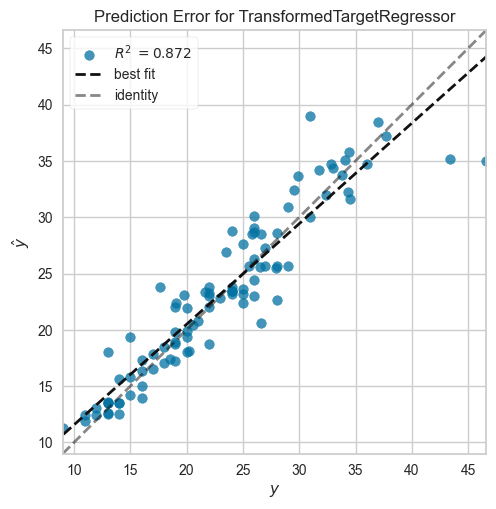

In [46]:
# visualize prediction error of the model
visualizer = PredictionError(search.best_estimator_, force_model=True)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test) # coefficient of determination score on test set
visualizer.finalize()

*A [prediction error plot](https://www.scikit-yb.org/en/latest/api/regressor/peplot.html) shows the actual $`y`$ targets from the dataset against the predicted $\hat{y}$ values generated by the model.*
* *This allows user to see where error is occurring, in what magnitude, and how much variance is in the model.*
* *The dotted grey line is the 45 degree line that indicates zero error —where the prediction exactly matches the model. Meanwhile, the dotted black line is a linear best fit; used to estimate the correlation between the predicted and measured value of the target variable.*

For a noise-free regression task aiming to predict the (conditional) expectation of $y$, a perfect regression model would display data points on the diagonal defined by predicted equal to actual values.
* In a more realistic setting with irreducible noise, that is, when not all the variations of $y$ can be explained by features in $X$, then the best model would lead to a cloud of points densely arranged around the diagonal —in which above plot also shows blue data points around the black linear best fit.
* Plot ini juga merupakan representasi visual dari test scores yang telah ditampilkan pada [Section 4: Evaluation Metrics](#evaluation-metrics).
    * Average absolute vertical distance from each point to the dashed line $y = x$ is the mean absolute error `mae` value of ~1.59.
    * `R2` value of 0.914 serves as measurement of how well actual values `y` are replicated by the model from `y_pred`, with ~91% variance of the actual values fall around the best fit line.

#### Residuals Plot

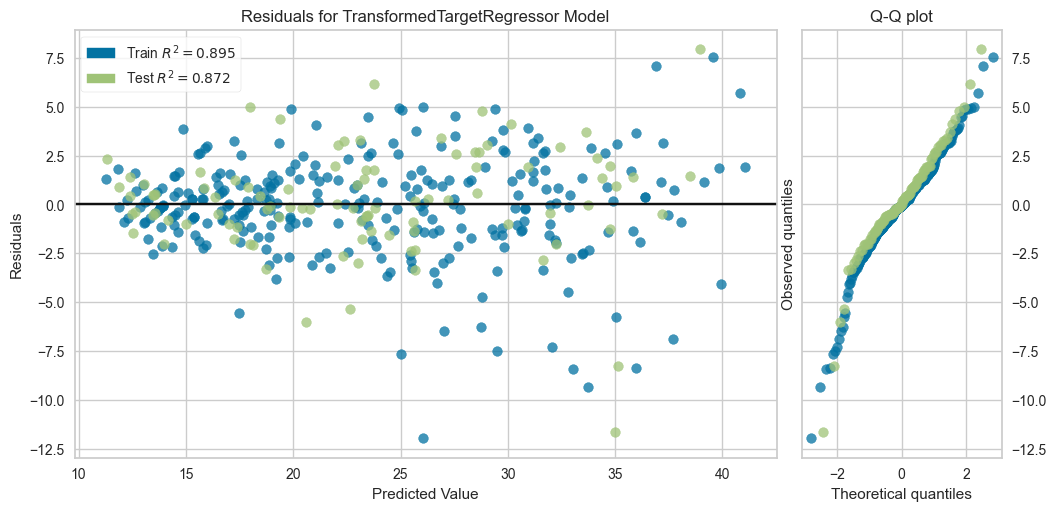

In [47]:
# plot residuals of the model against the predicted values
width, height = 10, 5
_, ax = plt.subplots(figsize=(width, height), layout="constrained")

visualizer = ResidualsPlot(
    search.best_estimator_,
    ax=ax,
    hist=False, # disable histogram of residuals as prerequisite for enabling QQ plot
    qqplot=True, 
    force_model=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.finalize()

*[Residuals](https://www.scikit-yb.org/en/latest/api/regressor/residuals.html), in the context of regression models, are the difference between the observed value of the target variable and the predicted value; i.e. the error of the prediction.*
* *Residuals plot on the left side shows the difference between residuals on the vertical axis and the dependent variable on the horizontal axis.*
* *Q-Q plot on the right side displays a quantile-quantile plot from quantiles of the sample data (residuals) versus the theoretical quantile values from a normal distribution; essentially assessing the normality of the residuals.*

In fitting a linear least squares regression model —in which `ElasticNet` termasuk dalam kategori model ini—, these plots can be used to check if some of the [model assumptions](https://en.wikipedia.org/wiki/Ordinary_least_squares#Assumptions) are met, as elaborated below:
1. Generally, the shape of the residuals membentuk random cloud around dashed horizontal line of zero residual, with no particular curved pattern observed —indicating a plausible [**linearity**](https://en.wikipedia.org/wiki/Ordinary_least_squares#Assumptions) of the parameters and predictor variables toward the mean of the response variable.
2. In an ideal model with homoscedastic residuals, errors would be randomly scattered around zero across all prediction ranges with constant variance. However, the residuals plot reveals a pronounced funnel-shaped non-equal variance or **heteroscedastic** issue:
    * Lower predictions (10-20 MPG): Residuals are tightly concentrated around zero, indicating good model fit and stable error variance in this range.
    * Mid-range predictions (20-30 MPG): Variability begins to increase, with residuals spreading wider but still centered.
    * Higher predictions (30+ MPG): Residuals show dramatically increased spread with a notable positive bias—the model tends to underpredict MPG for fuel-efficient cars, systematically producing predictions that are too conservative.
    * Train and test residuals follow the same funnel pattern, confirming this as a genuine model limitation rather than overfitting.
3. Additionally, residual quantiles in the Q-Q plot bends away from the reference trend at the tails —especially the lower tail—, which indicates **non-normal** residual.

### Model Interpretation

*Predictive performance is often the main goal of developing machine learning models. Yet summarizing performance with an evaluation metric is often insufficient: it assumes that the evaluation metric and test dataset perfectly reflect the target domain, which is rarely true. In certain domains, a model needs a certain level of interpretability —to understand the predictions from a model and what affects them.*

#### Model Mechanism

[Elastic-Net](https://scikit-learn.org/stable/modules/linear_model.html#elastic-net) adalah salah satu dari [linear regression](https://en.wikipedia.org/wiki/Linear_regression) models, in which the target value is expected to be a linear combination of the features.
* In mathematical notation, the predicted value $\hat{y}$ can be written as: $\hat{y} = \beta _0 + \beta _1X_1 + ... + \beta_pX_p + \epsilon$
    * The predicted outcome of an instance $\hat{y}$ is a weighted sum of its $p$ features ($X$).
    * The betas $\beta_i,\ i ∈ 1, ... ,\ p$ represent the learned feature weights or coefficients.
    * The first weight in the sum $\beta _0$ is called the intercept and is not multiplied with a feature.
    * The epsilon $ε$ is the prediction error we still make, i.e. the difference between the prediction and the actual outcome.
* Specifically, `ElasticNet` is trained with [regularized least squares](https://en.wikipedia.org/wiki/Regularized_least_squares) of $l_1$ and $l_2$-norm of the coefficients.
    * [Least squares](https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares) method —in linear or ordinary term (OLS)— fits a model with the coefficients to minimize the residual sum of squares between observed target $y$ in the dataset, and the target predicted by the linear approximation $\hat{y}$.
        * Mathematically it solves a problem of the form: $\min_{\beta} = ||X\beta - y||_2^2$
        * The coefficient estimates for OLS rely on the independence of the features. When features are correlated and some columns of the design matrix $X$ have an approximately linear dependence, the design matrix becomes close to singular and as a result, the least-squares estimate becomes highly sensitive to random errors in the observed target, producing a large variance.
    * $l_2$-norm a.k.a. [Ridge](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification) regression addresses aforementioned problem by imposing a penalty (as part of the [regularization](https://en.wikipedia.org/wiki/Regularization_(mathematics))) on the size of the coefficients.
        * The ridge coefficients minimize a penalized residual sum of squares: $\min_{\beta} = ||X\beta - y||_2^2 + \alpha||\beta||_2^2$
        * The complexity parameter $\alpha \geq 0$ controls the amount of shrinkage: the larger the value of $\alpha$, the greater the amount of shrinkage and thus the coefficients become more robust to collinearity.
    * $l_1$-norm or [Lasso](https://scikit-learn.org/stable/modules/linear_model.html#lasso) is a linear model that estimates sparse coefficients, i.e., it is able to set coefficients exactly to zero.
        * The objective function to minimize also comes with an added regularization term: $\min_{\beta} = {\frac{1}{2n_{\text{samples}}} ||X\beta - y|_2^2 + \alpha||\beta||_1}$
        * It is useful in some contexts due to its tendency to prefer solutions with fewer non-zero coefficients, effectively reducing the number of features upon which the given solution is dependent resulting in enhanced prediction accuracy and interpretability of the model.
    * Elastic-Net linearly combines the $l_1$ and $l_2$ penalties of Lasso and Ridge methods, respectively.
        * The objective function to minimize is in this case: $\min_{\beta} = {\frac{1}{2n_{\text{samples}}} ||X\beta - y||_2^2 + \alpha \rho ||\beta||_1 + \frac{\alpha(1 - \rho)}{2}||\beta||_2^2}$
        * The mixing parameter $0 \leq \rho \leq 1$ controls the combination of $l_1$ and $l_2$. This combination allows for learning a sparse model where few of the weights are non-zero like Lasso, while still maintaining the regularization properties of Ridge.
* `ElasticNet` stores the coefficients $\beta$ of the linear model in its `coef_` attribute as shown below:

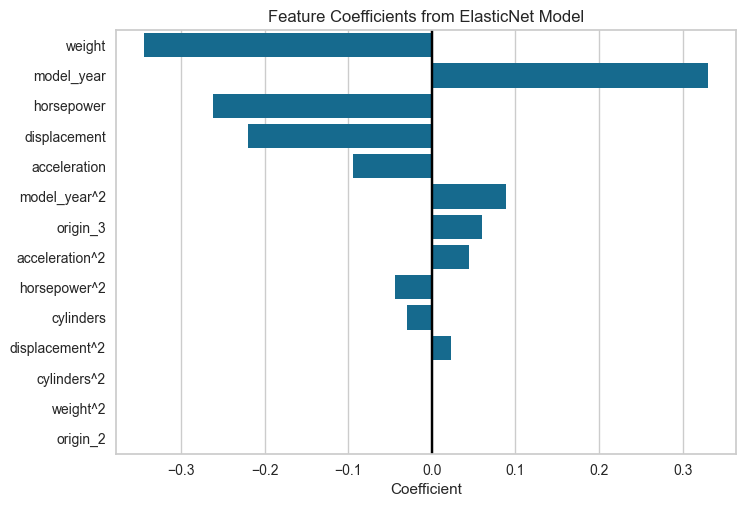

In [ ]:
# access model coefficients from tuned estimator
coefs = search.best_estimator_["transformedtargetregressor"].regressor_.coef_
feature_names = search.best_estimator_["preprocessor"].get_feature_names_out()
df_coefs = pd.DataFrame(coefs, columns=["Coefficient"], index=feature_names)

# plot visualization for model coefficients     
order = abs(df_coefs["Coefficient"]).sort_values(ascending=False).index
sns.barplot(df_coefs, x="Coefficient", y=df_coefs.index, order=order)

plt.title("Feature Coefficients from ElasticNet Model")
plt.axvline(x=0, color="black")
plt.ylabel(None)
plt.show()

* Tetapi violations of linear regression assumptions as detected on [Section 4: Residuals Plot](#residuals-plot) can [result](https://en.wikipedia.org/wiki/Ordinary_least_squares#Assumptions) in biased estimations of $β$, biased standard errors, untrustworthy confidence intervals and significance tests.
* Another way to explain how each of these feature contributed to the prediction is by using [Shapley Additive Explanations](https://shap.readthedocs.io/en/latest/) —a game theoretic approach using the classic Shapley Values from game theory to explain the output of machine learning model— as explored in the next section.

#### Shapley Additive Explanations

In [49]:
# Extract the preprocessed test data and the fitted model step
X_test_t = search.best_estimator_["preprocessor"].transform(X_test)
model = search.best_estimator_["transformedtargetregressor"]

masker = shap.maskers.Independent(X_test_t, max_samples=len(X_test_t))
explainer = shap.Explainer(model.predict, masker, seed=seed)
shap_values = explainer(X_test_t, silent=True)

# Assign feature names directly to the SHAP explanation object
shap_values.feature_names = list(feature_names)

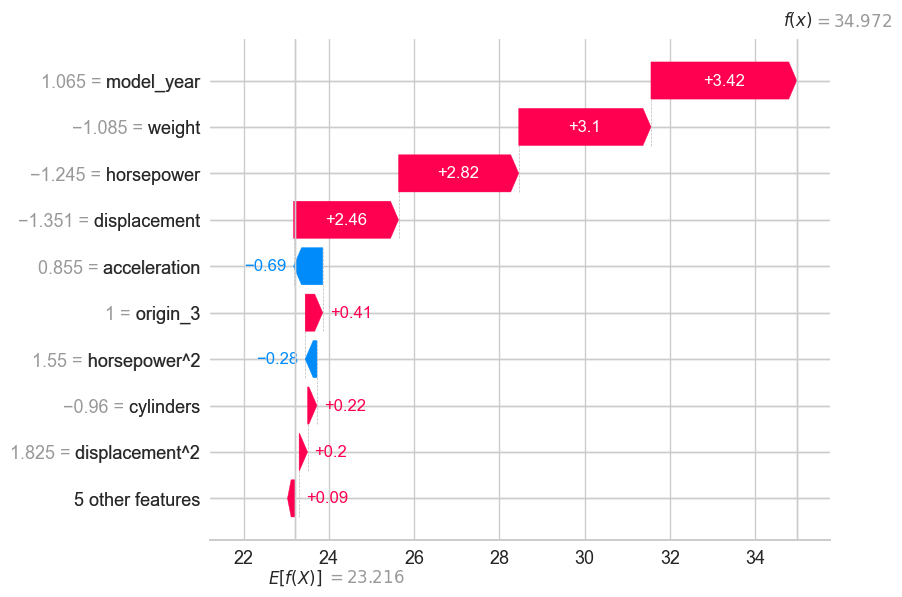

In [50]:
X_test_transformed = pd.DataFrame(X_test_t, columns=feature_names, index=X_test.index)
resid = pd.DataFrame([y_pred - y_test], index=["resid"]).transpose()
test_transformed_pred = pd.concat([X_test_transformed, y_test, y_pred, resid], axis=1)
test_transformed_pred = test_transformed_pred.reset_index(drop=True)

mask_resid_idxmin = test_transformed_pred["resid"].idxmin()
shap.plots.waterfall(shap_values[mask_resid_idxmin])

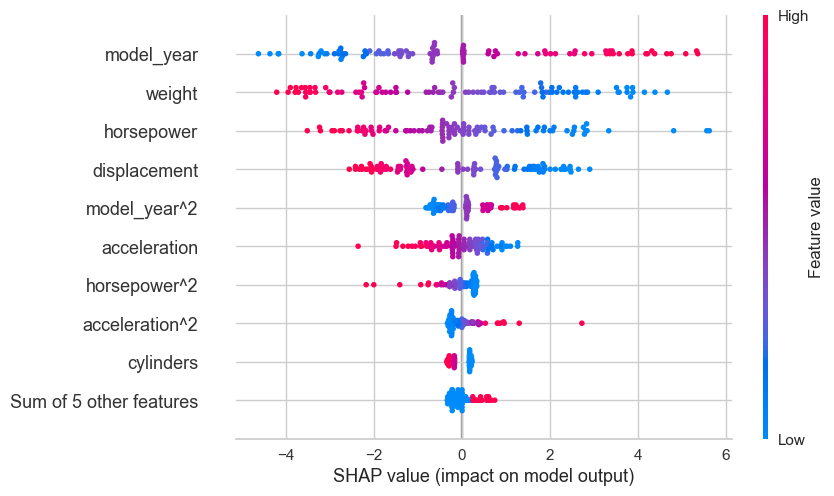

In [51]:
shap.plots.beeswarm(shap_values)

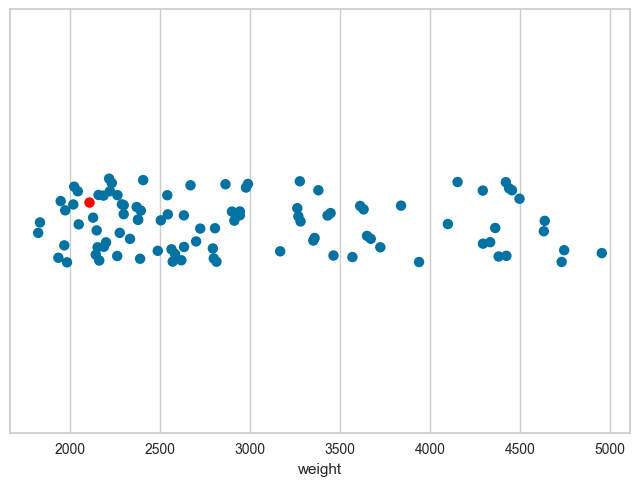

In [77]:
test_pred = pd.concat([X_test, y_test, y_pred, resid], axis=1)
hue = test_pred["resid"] == test_pred["resid"].min()

sns.stripplot(
    data=test_pred,
    x="weight",
    hue=hue,
    palette={
        True: "red",
        False: "C0"
    },
    legend=False,
    size=7.5
)
plt.show()

* For machine learning models this means that SHAP values of all the input features will always sum up to the difference between baseline (expected) model output and the current model output for the prediction being explained.
* The easiest way to see this is through a waterfall plot that starts at our background prior expectation for a home price 𝐸⁡[𝑓⁡(𝑋)], and then adds features one at a time until we reach the current model output 𝑓⁡(𝑥)

---